The autoregressive Transformer walkthrough built a model that predicts the **next**
token, and had to hide the future behind a causal mask to do it.

BERT throws that mask away.

Its training task is not "what comes next" but "what is missing": some inputs are
blanked out, and the model reconstructs them using context from **both sides**. That
single change &mdash; bidirectional instead of causal &mdash; is what makes BERT an *encoder* of
meaning rather than a *generator* of sequences.

Here the inputs are not words but **EEG**. A raw multi-channel recording is cut into
short time patches, each patch is projected into a vector, some patches are masked, and
the encoder reconstructs them. This is exactly how EEG foundation models are pre-trained,
and it maps onto BERT with one substitution:

| BERT on text | BERT on EEG |
|---|---|
| token &rarr; embedding **lookup** | patch &rarr; linear **projection** |
| predict token ID, cross-entropy | predict the waveform, **MSE** |
| vocabulary softmax | reconstruction head |

Everything below is computed in NumPy with every matrix printed, and each hand
computation is checked against the array it came from.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Signal

Two channels of synthetic EEG, one second at 64 Hz. Both carry a background alpha rhythm
(~10 Hz); a spike-wave burst is injected in the middle, which is the interesting event a
model would need to represent.

In [2]:
FS          = 64          # sampling rate (Hz)
DURATION    = 1.0         # seconds
N_CHANNELS  = 2
PATCH_LEN   = 8           # samples per patch
D_MODEL     = 8
N_HEADS     = 2
D_K         = D_MODEL // N_HEADS
D_FF        = 16
MASK_RATIO  = 0.25

t = np.arange(0, DURATION, 1 / FS)
n_time = len(t)

alpha = np.sin(2 * np.pi * 10 * t)
spike = np.zeros(n_time)
burst = slice(24, 40)
spike[burst] = 2.4 * np.sin(2 * np.pi * 3 * t[burst]) * np.hanning(16)

eeg = np.vstack([
    0.8 * alpha + spike + 0.05 * np.random.randn(n_time),
    0.6 * np.sin(2 * np.pi * 10 * t + 0.7) + 0.8 * spike + 0.05 * np.random.randn(n_time),
])
ch_names = ["Fp1", "Fp2"]

print(f"EEG array shape: {eeg.shape}  ({N_CHANNELS} channels x {n_time} samples)")
print(f"sampling rate {FS} Hz, duration {DURATION}s, spike burst at samples "
      f"{burst.start}-{burst.stop}\n")
print(f"{'sample':>7}  {'time(s)':>8}  " + "  ".join(f"{c:>9}" for c in ch_names))
print("-" * 40)
for i in list(range(6)) + [None] + list(range(28, 34)):
    if i is None:
        print(f"{'...':>7}")
        continue
    print(f"{i:>7}  {t[i]:>8.4f}  " + "  ".join(f"{eeg[c, i]:>9.4f}" for c in range(N_CHANNELS)))
print("-" * 40)
print(f"\nmean {eeg.mean():+.4f}, std {eeg.std():.4f}")

EEG array shape: (2, 64)  (2 channels x 64 samples)
sampling rate 64 Hz, duration 1.0s, spike burst at samples 24-40

 sample   time(s)        Fp1        Fp2
----------------------------------------
      0    0.0000     0.0248     0.4272
      1    0.0156     0.6583     0.6641
      2    0.0312     0.7715     0.2725
      3    0.0469     0.2322    -0.2394
      4    0.0625    -0.5774    -0.5797
      5    0.0781    -0.7963    -0.4069
    ...
     28    0.4375     1.7602     0.9957
     29    0.4531     1.2208     0.6281
     30    0.4688     0.4369     0.3733
     31    0.4844     0.1165     0.3113
     32    0.5000    -0.0007     0.4013
     33    0.5156    -0.0179     0.1052
----------------------------------------

mean +0.0234, std 0.5996


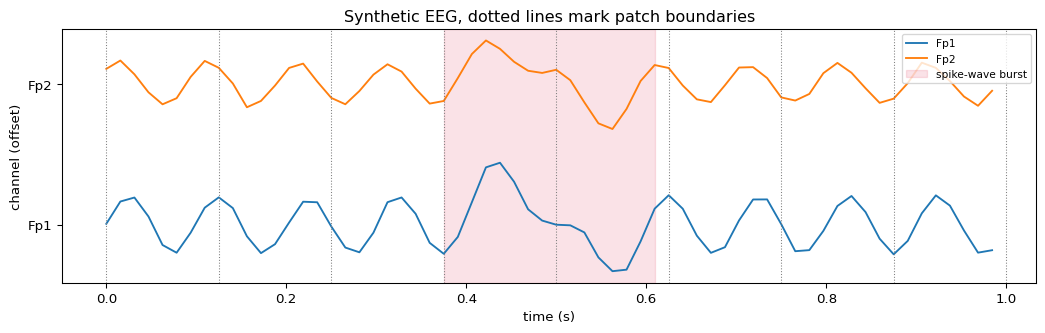

The dotted lines cut the recording into 8 patches of 8 samples each.
Those patches are this model's 'tokens'.


In [3]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for c in range(N_CHANNELS):
    ax.plot(t, eeg[c] + c * 4, lw=1.4, label=ch_names[c])
ax.axvspan(t[burst.start], t[burst.stop - 1], color="crimson", alpha=.12,
           label="spike-wave burst")
for k in range(0, n_time + 1, PATCH_LEN):
    ax.axvline(k / FS, color="grey", ls=":", lw=.8)
ax.set(xlabel="time (s)", ylabel="channel (offset)", title="Synthetic EEG, dotted lines mark patch boundaries")
ax.set_yticks([0, 4], ch_names)
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

print(f"The dotted lines cut the recording into {n_time // PATCH_LEN} patches of "
      f"{PATCH_LEN} samples each.")
print("Those patches are this model's 'tokens'.")

---
# 2. Patching &mdash; Turning a Signal into Tokens

A Transformer needs a *sequence of vectors*. Feeding one time sample per position would
give 64 positions carrying almost no information each, and attention cost grows with the
square of that number.

So the signal is cut into non-overlapping patches, and each patch is flattened across
channels:

$$\text{patch}_p \in \mathbb{R}^{C \times L} \;\longrightarrow\; \mathbb{R}^{C \cdot L}$$

with $C = 2$ channels and $L = 8$ samples, giving vectors of length 16.

In [4]:
n_patches = n_time // PATCH_LEN
PATCH_DIM = N_CHANNELS * PATCH_LEN

patches = np.stack([eeg[:, p*PATCH_LEN:(p+1)*PATCH_LEN].reshape(-1)
                    for p in range(n_patches)])
patch_names = [f"p{p}" for p in range(n_patches)]

print(f"{n_patches} patches x {PATCH_DIM} values  ->  patches.shape = {patches.shape}\n")
print(f"patch p3 covers samples {3*PATCH_LEN}..{4*PATCH_LEN-1} "
      f"(t = {3*PATCH_LEN/FS:.3f}s to {(4*PATCH_LEN-1)/FS:.3f}s)\n")
print(f"   {ch_names[0]} values: {np.round(eeg[0, 24:32], 4)}")
print(f"   {ch_names[1]} values: {np.round(eeg[1, 24:32], 4)}")
print(f"   flattened          : {np.round(patches[3], 4)}")
print(f"   MATCH: {np.allclose(patches[3], np.concatenate([eeg[0,24:32], eeg[1,24:32]]))}")

print()
show_matrix(patches, "patches", rows=patch_names, max_cols=16)
print(f"\nrow energy (how active each patch is):")
for p in range(n_patches):
    e = np.linalg.norm(patches[p])
    bar = "#" * int(e * 4)
    tag = "  <- spike burst" if 3 <= p <= 4 else ""
    print(f"   {patch_names[p]}: {e:>7.4f}  {bar}{tag}")

8 patches x 16 values  ->  patches.shape = (8, 16)

patch p3 covers samples 24..31 (t = 0.375s to 0.484s)

   Fp1 values: [-0.8272 -0.3474  0.638   1.6286  1.7602  1.2208  0.4369  0.1165]
   Fp2 values: [-0.4854  0.1653  0.8491  1.2341  0.9957  0.6281  0.3733  0.3113]
   flattened          : [-0.8272 -0.3474  0.638   1.6286  1.7602  1.2208  0.4369  0.1165 -0.4854  0.1653  0.8491  1.2341  0.9957  0.6281  0.3733  0.3113]
   MATCH: True

patches (8, 16) =
           p0 |   +0.025    +0.658    +0.771    +0.232    -0.577    -0.796    -0.227    +0.483    +0.427    +0.664    +0.272    -0.239    -0.580    -0.407    +0.200    +0.653
           p1 |   +0.777    +0.472    -0.329    -0.808    -0.554    +0.060    +0.653    +0.637    +0.457    +0.012    -0.664    -0.484    -0.047    +0.454    +0.576    +0.067
           p2 |   -0.051    -0.649    -0.785    -0.227    +0.639    +0.773    +0.310    -0.516    -0.398    -0.578    -0.202    +0.264    +0.557    +0.350    -0.136    -0.560
           p3 |   

---
# 3. Patch Embedding

Text BERT looks a token ID up in an embedding table. There is no table here &mdash; the input
is continuous &mdash; so the patch is **projected** instead:

$$E_p = \text{patch}_p W_e + b_e, \qquad W_e \in \mathbb{R}^{16 \times 8}$$

This is the only structural difference at the input, and it is why the same architecture
transfers to signals, images (ViT), and audio.

In [5]:
def xavier(fan_in, fan_out):
    a = np.sqrt(6.0 / (fan_in + fan_out))
    return np.random.uniform(-a, a, size=(fan_in, fan_out))

W_e = xavier(PATCH_DIM, D_MODEL)
b_e = np.zeros(D_MODEL)
E_patch = patches @ W_e + b_e

show_matmul(patches, W_e, E_patch, "patches", "W_e", "E_patch",
            rows_A=patch_names, i=3, j=0,
            note="each 16-value patch becomes an 8-dim vector")

  patches (8, 16)   @   W_e (16, 8)   =   E_patch (8, 8)
  shape rule: (8 x 16) @ (16 x 8) -> (8 x 8)   inner dim 16 cancels
  each 16-value patch becomes an 8-dim vector

patches (8, 16)   [first 14 of 16 columns] =
           p0 |   +0.025    +0.658    +0.771    +0.232    -0.577    -0.796    -0.227    +0.483    +0.427    +0.664    +0.272    -0.239    -0.580    -0.407
           p1 |   +0.777    +0.472    -0.329    -0.808    -0.554    +0.060    +0.653    +0.637    +0.457    +0.012    -0.664    -0.484    -0.047    +0.454
           p2 |   -0.051    -0.649    -0.785    -0.227    +0.639    +0.773    +0.310    -0.516    -0.398    -0.578    -0.202    +0.264    +0.557    +0.350
           p3 |   -0.827    -0.347    +0.638    +1.629    +1.760    +1.221    +0.437    +0.117    -0.485    +0.165    +0.849    +1.234    +0.996    +0.628
           p4 |   -0.001    -0.018    -0.220    -0.930    -1.321    -1.278    -0.474    +0.454    +0.401    +0.105    -0.524    -1.121    -1.281    -0.712
        

### The `[CLS]` token and positional encoding

Two additions, both borrowed unchanged from text BERT:

**`[CLS]`** is a learned vector prepended to the sequence. It belongs to no patch, so it
is free to accumulate a summary of the whole recording through attention &mdash; which is
what a downstream classifier reads.

**Positional encoding** restores order. Attention is permutation-invariant: without it,
a spike at 0.4s and the same spike at 0.9s would be indistinguishable.

$$Z = \big[\,\texttt{[CLS]};\, E_0;\, \dots;\, E_{7}\,\big] + PE$$

In [6]:
def positional_encoding(seq_len, d_model):
    pos = np.arange(seq_len)[:, None]
    i = np.arange(d_model)[None, :]
    angle = pos / np.power(10000, (2 * (i // 2)) / d_model)
    pe = np.zeros((seq_len, d_model))
    pe[:, 0::2] = np.sin(angle[:, 0::2])
    pe[:, 1::2] = np.cos(angle[:, 1::2])
    return pe

CLS = np.random.randn(D_MODEL) / np.sqrt(D_MODEL)
seq = np.vstack([CLS, E_patch])
seq_names = ["[CLS]"] + patch_names
n_seq = len(seq)

PE = positional_encoding(n_seq, D_MODEL)
Z0 = seq + PE

print(f"sequence length = 1 ([CLS]) + {n_patches} patches = {n_seq}\n")
print(f"[CLS] vector = {np.round(CLS, 4)}\n")
show_elementwise(seq, PE, Z0, "embeddings", "PE", "Z0", "+", rows=seq_names)

sequence length = 1 ([CLS]) + 8 patches = 9

[CLS] vector = [-0.2529  0.2403 -0.2582  0.0765  0.0161 -0.2304  0.758   0.2241]

  Z0 = embeddings + PE      all three are (9, 8) - element-wise

     [CLS] |
       embeddings:   -0.253    +0.240    -0.258    +0.077    +0.016    -0.230    +0.758    +0.224
               PE:   +0.000    +1.000    +0.000    +1.000    +0.000    +1.000    +0.000    +1.000
               Z0:   -0.253    +1.240    -0.258    +1.077    +0.016    +0.770    +0.758    +1.224

        p0 |
       embeddings:   +0.176    +0.479    +0.472    -1.184    -0.219    -0.029    -0.147    +0.664
               PE:   +0.841    +0.540    +0.100    +0.995    +0.010    +1.000    +0.001    +1.000
               Z0:   +1.018    +1.020    +0.572    -0.189    -0.209    +0.971    -0.146    +1.664

        p1 |
       embeddings:   -1.002    -0.174    +0.819    -0.394    -0.141    -0.775    +0.782    -0.666
               PE:   +0.909    -0.416    +0.199    +0.980    +0.020    +1.000    

---
# 4. Masking

BERT's training signal comes from hiding part of the input. A fraction of positions is
selected, and the chosen ones are replaced by a single learned **`[MASK]`** vector.

Text BERT applies the well-known 80/10/10 rule to each selected position:

* 80% replaced by `[MASK]`,
* 10% replaced by a random token,
* 10% left unchanged.

The reason is a train/inference mismatch: `[MASK]` never appears when the model is
actually used, so if every selected position were masked the model would only ever learn
to handle that symbol. The 10% "unchanged" slice forces it to keep a good representation
of *every* position, because it cannot tell which ones it will be scored on.

In [7]:
MASK_VEC = np.random.randn(D_MODEL) / np.sqrt(D_MODEL)

patch_positions = np.arange(1, n_seq)          # position 0 is [CLS], never masked
n_mask = max(1, int(round(MASK_RATIO * n_patches)))
masked_pos = np.sort(np.random.choice(patch_positions, size=n_mask, replace=False))

Z = Z0.copy()
for p in masked_pos:
    Z[p] = MASK_VEC + PE[p]      # replace content, keep the position signal

print(f"masking {MASK_RATIO:.0%} of {n_patches} patches -> {n_mask} positions\n")
print(f"[MASK] vector = {np.round(MASK_VEC, 4)}\n")
print(f"{'pos':>5}  {'name':>7}  {'masked':>7}  {'input row (after masking)':>30}")
print("-" * 62)
for p in range(n_seq):
    tag = "YES" if p in masked_pos else "-"
    print(f"{p:>5}  {seq_names[p]:>7}  {tag:>7}  {np.round(Z[p], 3)}")
print("-" * 62)

print(f"\nmasked positions: {masked_pos.tolist()} = "
      f"{[seq_names[p] for p in masked_pos]}")
print(f"\nThe true content of those patches is kept aside as the reconstruction")
print(f"target - the encoder never sees it again until the loss is computed.")
targets = patches[masked_pos - 1]
print(f"targets.shape = {targets.shape}  ({n_mask} patches x {PATCH_DIM} values)")

masking 25% of 8 patches -> 2 positions

[MASK] vector = [-0.716   0.0659 -0.234   0.3014 -0.2802 -0.0406  0.1785  0.3061]

  pos     name   masked       input row (after masking)
--------------------------------------------------------------
    0    [CLS]        -  [-0.253  1.24  -0.258  1.077  0.016  0.77   0.758  1.224]
    1       p0        -  [ 1.018  1.02   0.572 -0.189 -0.209  0.971 -0.146  1.664]
    2       p1        -  [-0.092 -0.59   1.018  0.586 -0.121  0.225  0.784  0.334]
    3       p2        -  [ 0.056 -1.426 -0.251  2.104  0.252  0.99  -0.005  0.365]
    4       p3      YES  [-1.473 -0.588  0.155  1.222 -0.24   0.959  0.183  1.306]
    5       p4        -  [-2.342 -0.051  0.508  0.071 -0.7    1.166  0.193  0.106]
    6       p5        -  [-1.374  0.887  1.368  0.389  0.098  0.207  0.742  0.27 ]
    7       p6        -  [0.483 0.387 0.232 1.859 0.285 1.126 0.031 0.352]
    8       p7      YES  [ 0.273 -0.08   0.483  0.998 -0.2    0.956  0.187  1.306]
------------------

---
# 5. Bidirectional Self-Attention

This is the difference that defines BERT.

The autoregressive decoder added a causal mask $M$ before the softmax so position $t$
could not see beyond itself. BERT adds **nothing**:

$$A = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)
\qquad\text{(no } +M \text{ term)}$$

Every position attends to every other position, in both directions. A masked patch is
reconstructed from the signal **before and after** it &mdash; which is why BERT is useless
for generation and excellent for representation.

In [8]:
def softmax(x, axis=-1):
    x = x - np.max(x, axis=axis, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=axis, keepdims=True)

def split_heads(x, h=N_HEADS):
    n, d = x.shape
    return x.reshape(n, h, d // h).transpose(1, 0, 2)

def merge_heads(x):
    h, n, dk = x.shape
    return x.transpose(1, 0, 2).reshape(n, h * dk)

Wq = xavier(D_MODEL, D_MODEL); Wk = xavier(D_MODEL, D_MODEL)
Wv = xavier(D_MODEL, D_MODEL); Wo = xavier(D_MODEL, D_MODEL)

print("STEP 1 : project Z to Q, K, V")
print("=" * 78)
Q_full = Z @ Wq
show_matmul(Z, Wq, Q_full, "Z", "Wq", "Q_full", rows_A=seq_names,
            note="K uses Wk, V uses Wv - identical arithmetic")
K_full, V_full = Z @ Wk, Z @ Wv
print(f"\nK_full {K_full.shape}, V_full {V_full.shape}")

Qh, Kh, Vh = split_heads(Q_full), split_heads(K_full), split_heads(V_full)
print(f"\nSTEP 2 : split into {N_HEADS} heads of {D_K}  ->  {Qh.shape}")

STEP 1 : project Z to Q, K, V
  Z (9, 8)   @   Wq (8, 8)   =   Q_full (9, 8)
  shape rule: (9 x 8) @ (8 x 8) -> (9 x 8)   inner dim 8 cancels
  K uses Wk, V uses Wv - identical arithmetic

Z (9, 8) =
        [CLS] |   -0.253    +1.240    -0.258    +1.077    +0.016    +0.770    +0.758    +1.224
           p0 |   +1.018    +1.020    +0.572    -0.189    -0.209    +0.971    -0.146    +1.664
           p1 |   -0.092    -0.590    +1.018    +0.586    -0.121    +0.225    +0.784    +0.334
           p2 |   +0.056    -1.426    -0.251    +2.104    +0.252    +0.990    -0.005    +0.365
           p3 |   -1.473    -0.588    +0.155    +1.222    -0.240    +0.959    +0.183    +1.306
           p4 |   -2.342    -0.051    +0.508    +0.071    -0.700    +1.166    +0.193    +0.106
           p5 |   -1.374    +0.887    +1.368    +0.389    +0.098    +0.207    +0.742    +0.270
           p6 |   +0.483    +0.387    +0.232    +1.859    +0.285    +1.126    +0.031    +0.352
           p7 |   +0.273    -0.080    +0

In [9]:
print("STEP 3 : scores = Q K^T / sqrt(d_k)   (head 0)")
print("=" * 78)
raw = Qh[0] @ Kh[0].T
scores = raw / np.sqrt(D_K)
show_matmul(Qh[0], Kh[0].T, raw, "Q_head0", "K_head0^T", "raw_scores",
            rows_A=seq_names, note=f"({n_seq},{D_K}) @ ({D_K},{n_seq}) -> ({n_seq},{n_seq})")

print(f"\n\nthen divide every entry by sqrt(d_k) = {np.sqrt(D_K):.0f}:\n")
show_matrix(scores, "scaled_scores", rows=seq_names, max_cols=n_seq)

print("\n\nSTEP 4 : softmax - and note what is NOT here")
print("=" * 78)
A0 = softmax(scores)
show_matrix(A0, "A = softmax(scores)", rows=seq_names, fmt="{:8.4f}", max_cols=n_seq)

print(f"\nrow sums (must all be 1): {np.round(A0.sum(axis=1), 6)}")
upper = np.triu(np.ones((n_seq, n_seq), dtype=bool), k=1)
print(f"\nentries ABOVE the diagonal - the 'future' - are all non-zero: "
      f"{np.all(A0[upper] > 0)}")
print(f"   smallest such weight = {A0[upper].min():.6f}")
print(f"\nIn the autoregressive decoder every one of those was exactly 0.")
print(f"That is the whole difference between BERT and GPT, visible as a matrix.")

STEP 3 : scores = Q K^T / sqrt(d_k)   (head 0)
  Q_head0 (9, 4)   @   K_head0^T (4, 9)   =   raw_scores (9, 9)
  shape rule: (9 x 4) @ (4 x 9) -> (9 x 9)   inner dim 4 cancels
  (9,4) @ (4,9) -> (9,9)

Q_head0 (9, 4) =
        [CLS] |   +0.411    -1.174    +0.042    -0.161
           p0 |   -0.185    -0.180    -1.390    -0.522
           p1 |   -0.550    +0.497    -0.553    -0.323
           p2 |   +0.202    -0.321    +0.636    +2.178
           p3 |   +0.440    +0.745    +0.346    -0.227
           p4 |   +0.763    +1.369    +0.024    -1.488
           p5 |   +0.188    +0.675    -0.117    -1.785
           p6 |   +0.440    -1.112    +0.222    +1.315
           p7 |   -0.091    -0.081    -0.539    +0.210

K_head0^T (4, 9) =
            0 |   +1.036    -0.694    +0.844    +2.334    +2.509    +2.331    +0.533    +1.051    +1.041
            1 |   +0.552    -0.626    +0.651    +1.874    +1.032    +0.878    +0.211    +1.207    +0.562
            2 |   -0.206    +0.305    +0.055    -0.981  

### Bidirectional vs causal, side by side

The same scores, softmaxed twice: once as BERT does it, once with the causal mask the
decoder-style model would apply.

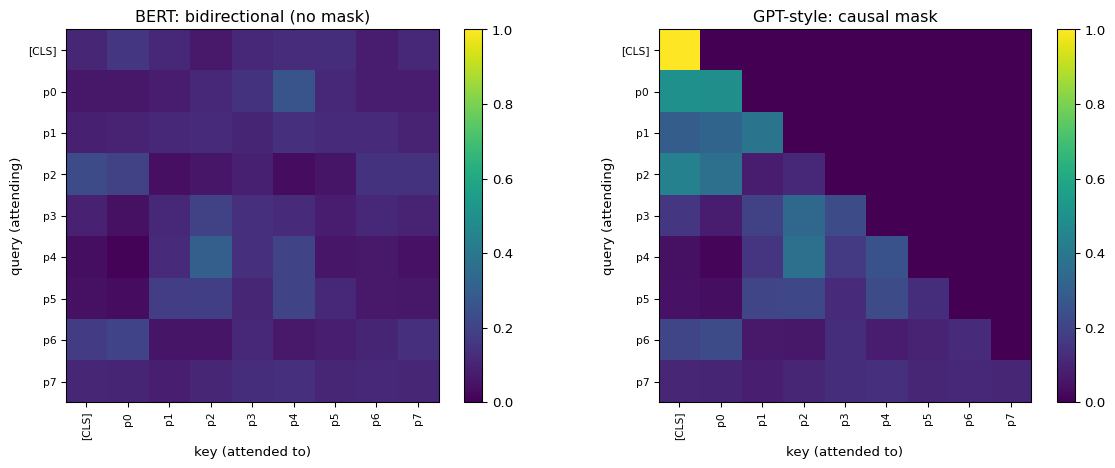

  query    BERT: non-zero weights    causal: non-zero weights
--------------------------------------------------------------
  [CLS]                         9                           1
     p0                         9                           2
     p1                         9                           3
     p2                         9                           4
     p3                         9                           5
     p4                         9                           6
     p5                         9                           7
     p6                         9                           8
     p7                         9                           9
--------------------------------------------------------------

Every BERT row uses all 9 positions. The causal rows grow 1, 2, 3, ...
A masked patch in the middle of the recording therefore gets context from
BOTH sides under BERT, and only from the left under a causal model.


In [10]:
causal = np.triu(np.ones((n_seq, n_seq), dtype=bool), k=1)
A_causal = softmax(np.where(causal, -1e9, scores))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
for ax, M, ttl in zip(axes, [A0, A_causal],
                      ["BERT: bidirectional (no mask)", "GPT-style: causal mask"]):
    im = ax.imshow(M, cmap="viridis", vmin=0, vmax=max(A0.max(), A_causal.max()))
    ax.set_xticks(range(n_seq), seq_names, rotation=90, fontsize=8)
    ax.set_yticks(range(n_seq), seq_names, fontsize=8)
    ax.set(xlabel="key (attended to)", ylabel="query (attending)", title=ttl)
    plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()

print(f"{'query':>7}  {'BERT: non-zero weights':>24}  {'causal: non-zero weights':>26}")
print("-" * 62)
for p in range(n_seq):
    print(f"{seq_names[p]:>7}  {int((A0[p] > 1e-9).sum()):>24}  "
          f"{int((A_causal[p] > 1e-9).sum()):>26}")
print("-" * 62)
print(f"\nEvery BERT row uses all {n_seq} positions. The causal rows grow 1, 2, 3, ...")
print(f"A masked patch in the middle of the recording therefore gets context from")
print(f"BOTH sides under BERT, and only from the left under a causal model.")

### One attention weight, by hand

$$A_{ij} = \frac{\exp(s_{ij} - m)}{\sum_{j'} \exp(s_{ij'} - m)},
\qquad s_{ij} = \frac{q_i \cdot k_j}{\sqrt{d_k}},
\qquad m = \max_{j} s_{ij}$$

In [11]:
qi = int(masked_pos[0])          # a masked patch, attending
kj = qi + 1 if qi + 1 < n_seq else qi - 1

q, k = Qh[0, qi], Kh[0, kj]
print(f"query = position {qi} ('{seq_names[qi]}', MASKED), key = position {kj} "
      f"('{seq_names[kj]}')\n")
print(f"q = {np.round(q, 6)}")
print(f"k = {np.round(k, 6)}\n")
print(f"q . k = {expand(q, k)}")
dot = float(np.dot(q, k))
print(f"      = {dot:+.6f}")
print(f"/ sqrt(d_k) = {dot:+.6f} / {np.sqrt(D_K):.0f} = {dot/np.sqrt(D_K):+.6f}")
print(f"from the scores matrix: {scores[qi, kj]:+.6f}   "
      f"MATCH: {np.isclose(dot/np.sqrt(D_K), scores[qi, kj])}\n")

s_row = scores[qi]
m_ = s_row.max(); e_ = np.exp(s_row - m_); Zsum = e_.sum()
print(f"softmax over row {qi}, m = max = {m_:.6f}\n")
print(f"{'j':>4}  {'name':>7}  {'s_ij':>11}  {'s-m':>11}  {'exp':>10}  {'/Z':>10}  {'array':>10}")
print("-" * 70)
for j in range(n_seq):
    print(f"{j:>4}  {seq_names[j]:>7}  {s_row[j]:>11.6f}  {s_row[j]-m_:>11.6f}  "
          f"{e_[j]:>10.6f}  {e_[j]/Zsum:>10.6f}  {A0[qi, j]:>10.6f}")
print("-" * 70)
print(f"Z = {Zsum:.6f},  sum of weights = {(e_/Zsum).sum():.10f}")
print(f"MATCH with the array row: {np.allclose(e_/Zsum, A0[qi])}")

query = position 4 ('p3', MASKED), key = position 5 ('p4')

q = [ 0.4397  0.7448  0.3462 -0.2267]
k = [ 2.331   0.878  -1.9271  0.492 ]

q . k = (+0.4397)*(+2.3310) + (+0.7448)*(+0.8780) + (+0.3462)*(-1.9271) + (-0.2267)*(+0.4920)
      = +0.900163
/ sqrt(d_k) = +0.900163 / 2 = +0.450082
from the scores matrix: +0.450082   MATCH: True

softmax over row 4, m = max = 0.938971

   j     name         s_ij          s-m         exp          /Z       array
----------------------------------------------------------------------
   0    [CLS]     0.189236    -0.749735    0.472492    0.093338    0.093338
   1       p0    -0.504971    -1.443941    0.235996    0.046619    0.046619
   2       p1     0.410514    -0.528456    0.589514    0.116455    0.116455
   3       p2     0.938971     0.000000    1.000000    0.197544    0.197544
   4       p3     0.543256    -0.395714    0.673199    0.132986    0.132986
   5       p4     0.450082    -0.488889    0.613307    0.121155    0.121155
   6       p5     0

---
# 6. The Encoder Block

Identical in form to the encoder half of the autoregressive Transformer: attention,
residual + LayerNorm, feed-forward, residual + LayerNorm. Nothing here is BERT-specific
&mdash; the only BERT-specific choice was the absent mask.

In [12]:
def layer_norm(x, g, b, eps=1e-5):
    mu = x.mean(axis=-1, keepdims=True)
    var = x.var(axis=-1, keepdims=True)
    return g * (x - mu) / np.sqrt(var + eps) + b

A_all = softmax(np.einsum("hid,hjd->hij", Qh, Kh) / np.sqrt(D_K))
head_out = np.einsum("hij,hjd->hid", A_all, Vh)
concat = merge_heads(head_out)
attn_out = concat @ Wo

print("STEPS 5-7 : weights @ V, concat heads, project with W_O")
print("=" * 78)
show_matmul(A_all[0], Vh[0], head_out[0], "A_head0", "V_head0", "head0_out",
            rows_A=seq_names, note=f"({n_seq},{n_seq}) @ ({n_seq},{D_K}) -> ({n_seq},{D_K})")
print()
show_matmul(concat, Wo, attn_out, "concat", "W_O", "attn_out", rows_A=seq_names,
            note="W_O mixes the two heads")

g1, b1 = np.ones(D_MODEL), np.zeros(D_MODEL)
res1 = Z + attn_out
Z1 = layer_norm(res1, g1, b1)

print("\n\nAdd & Norm 1")
print("=" * 78)
show_elementwise(Z, attn_out, res1, "Z", "attn_out", "residual", "+", rows=seq_names)
print()
show_matrix(Z1, "Z1 = LayerNorm(residual)", rows=seq_names)
print(f"\nper-row mean ~ 0: {np.round(Z1.mean(axis=1), 6)}")
print(f"per-row std  ~ 1: {np.round(Z1.std(axis=1), 4)}")

STEPS 5-7 : weights @ V, concat heads, project with W_O
  A_head0 (9, 9)   @   V_head0 (9, 4)   =   head0_out (9, 4)
  shape rule: (9 x 9) @ (9 x 4) -> (9 x 4)   inner dim 9 cancels
  (9,9) @ (9,4) -> (9,4)

A_head0 (9, 9) =
        [CLS] |   +0.108    +0.157    +0.112    +0.069    +0.113    +0.125    +0.131    +0.075    +0.111
           p0 |   +0.064    +0.064    +0.082    +0.110    +0.147    +0.259    +0.115    +0.081    +0.077
           p1 |   +0.088    +0.097    +0.115    +0.124    +0.103    +0.134    +0.123    +0.118    +0.098
           p2 |   +0.232    +0.195    +0.042    +0.060    +0.089    +0.033    +0.056    +0.148    +0.145
           p3 |   +0.093    +0.047    +0.116    +0.198    +0.133    +0.121    +0.081    +0.115    +0.096
           p4 |   +0.038    +0.011    +0.123    +0.303    +0.139    +0.205    +0.061    +0.069    +0.051
           p5 |   +0.044    +0.032    +0.183    +0.187    +0.107    +0.203    +0.113    +0.068    +0.063
           p6 |   +0.179    +0.202    +0

In [13]:
W1, bf1 = xavier(D_MODEL, D_FF), np.zeros(D_FF)
W2, bf2 = xavier(D_FF, D_MODEL), np.zeros(D_MODEL)

lin1 = Z1 @ W1 + bf1
relu = np.maximum(0, lin1)
ffn = relu @ W2 + bf2

print("Feed-forward network:  8 -> 16 -> 8")
print("=" * 78)
show_matmul(Z1, W1, lin1, "Z1", "W1", "pre-ReLU", rows_A=seq_names)
print(f"\nReLU zeroes {int((relu == 0).sum())} of {relu.size} hidden activations "
      f"({(relu == 0).mean():.1%})\n")
show_matmul(relu, W2, ffn, "post-ReLU", "W2", "ffn_out", rows_A=seq_names)

g2, b2 = np.ones(D_MODEL), np.zeros(D_MODEL)
H = layer_norm(Z1 + ffn, g2, b2)

print("\n\nAdd & Norm 2  ->  ENCODER OUTPUT H")
print("=" * 78)
show_matrix(H, "H", rows=seq_names)
print(f"\nH.shape = {H.shape}   one contextual vector per position.")
print(f"Row 0 is the [CLS] summary; rows 1..{n_seq-1} are the contextualised patches.")

Feed-forward network:  8 -> 16 -> 8
  Z1 (9, 8)   @   W1 (8, 16)   =   pre-ReLU (9, 16)
  shape rule: (9 x 8) @ (8 x 16) -> (9 x 16)   inner dim 8 cancels

Z1 (9, 8) =
        [CLS] |   -1.317    +0.795    -0.619    -0.856    -0.920    +0.724    +1.706    +0.487
           p0 |   +0.450    +0.135    +0.526    -2.171    -1.038    +0.908    +0.296    +0.893
           p1 |   -0.227    -1.275    +1.336    -1.028    -0.577    +0.307    +1.728    -0.263
           p2 |   +0.077    -2.292    -0.273    +0.567    +0.049    +1.055    +1.077    -0.259
           p3 |   -1.645    -1.025    +0.316    -0.397    -0.565    +1.103    +1.138    +1.075
           p4 |   -1.775    +0.034    +0.853    -0.937    -0.663    +1.339    +0.992    +0.158
           p5 |   -1.665    +0.415    +1.477    -1.036    -0.393    +0.218    +1.238    -0.254
           p6 |   +0.099    -1.003    +0.042    +0.096    -0.763    +1.766    +1.154    -1.392
           p7 |   -0.126    -1.238    +0.585    -1.199    -1.155    +1.1

---
# 7. The Reconstruction Head and the Loss

Text BERT ends with a softmax over the vocabulary and a cross-entropy loss. There is no
vocabulary for a continuous signal, so the head projects each encoder output **back to
the patch dimension** and the loss is mean squared error:

$$\hat{p}_i = H_i W_r + b_r \in \mathbb{R}^{16},
\qquad
\mathcal{L} = \frac{1}{|\mathcal{M}|}\sum_{i \in \mathcal{M}} \big\lVert \hat{p}_i - p_i \big\rVert^2$$

Crucially the sum runs **only over the masked positions** $\mathcal{M}$. Unmasked
positions were handed to the model as input, so reconstructing them would be copying,
not learning.

In [14]:
W_r, b_r = xavier(D_MODEL, PATCH_DIM), np.zeros(PATCH_DIM)
recon = H[1:] @ W_r + b_r          # drop [CLS], one reconstruction per patch

print(f"reconstruction head: ({D_MODEL}) -> ({PATCH_DIM}) for each of {n_patches} patches")
print(f"recon.shape = {recon.shape}\n")

show_matmul(H[1:], W_r, recon, "H (patches only)", "W_r", "reconstruction",
            rows_A=patch_names, i=int(masked_pos[0]) - 1, j=0, max_cols=16)

reconstruction head: (8) -> (16) for each of 8 patches
recon.shape = (8, 16)

  H (patches only) (8, 8)   @   W_r (8, 16)   =   reconstruction (8, 16)
  shape rule: (8 x 8) @ (8 x 16) -> (8 x 16)   inner dim 8 cancels

H (patches only) (8, 8) =
           p0 |   +0.806    +0.897    +0.243    -1.745    -1.627    +0.260    +0.427    +0.738
           p1 |   +0.544    -0.334    +1.070    -0.956    -1.646    -0.097    +1.661    -0.242
           p2 |   +0.158    -1.918    -0.054    +1.098    -0.730    -0.230    +1.579    +0.097
           p3 |   -0.998    -0.393    +0.151    +0.555    -1.742    -0.171    +1.495    +1.103
           p4 |   -1.335    +0.845    +0.776    -0.420    -1.766    +0.468    +1.141    +0.292
           p5 |   -1.082    +1.079    +1.095    -1.086    -1.216    -0.095    +1.341    -0.036
           p6 |   +0.097    -0.377    +0.589    +0.317    -1.667    +1.184    +1.195    -1.339
           p7 |   +0.489    -0.210    +0.375    -0.385    -2.335    +0.137    +1.188    +0

In [15]:
mask_idx = masked_pos - 1
pred_m = recon[mask_idx]
true_m = patches[mask_idx]

per_patch = ((pred_m - true_m) ** 2).mean(axis=1)
loss = per_patch.mean()

print("LOSS - computed on masked patches only\n")
print(f"{'patch':>7}  {'masked':>7}  {'MSE':>10}  {'counts toward loss?':>20}")
print("-" * 50)
for p in range(n_patches):
    mse_p = ((recon[p] - patches[p]) ** 2).mean()
    is_m = p in set(mask_idx.tolist())
    print(f"{patch_names[p]:>7}  {'YES' if is_m else '-':>7}  {mse_p:>10.6f}  "
          f"{'YES' if is_m else 'no  (input, not a target)':>20}")
print("-" * 50)

print(f"\nmasked patches: {[patch_names[p] for p in mask_idx]}")
print(f"their MSEs    : {np.round(per_patch, 6)}")
print(f"\nloss = mean = ({' + '.join(f'{v:.6f}' for v in per_patch)}) / {len(per_patch)}")
print(f"     = {per_patch.sum():.6f} / {len(per_patch)} = {loss:.6f}")

p0 = mask_idx[0]
d = pred_m[0] - true_m[0]
manual = float((d ** 2).sum() / PATCH_DIM)
print(f"\nworked example, patch {patch_names[p0]}:")
print(f"   predicted[:4] = {np.round(pred_m[0][:4], 4)}")
print(f"   true[:4]      = {np.round(true_m[0][:4], 4)}")
print(f"   diff[:4]      = {np.round(d[:4], 4)}")
print(f"   sum of squares over {PATCH_DIM} values = {(d**2).sum():.6f}")
print(f"   / {PATCH_DIM} = {manual:.6f}")
print(f"   from array   = {per_patch[0]:.6f}   MATCH: {np.isclose(manual, per_patch[0])}")

baseline = ((true_m - true_m.mean()) ** 2).mean()
print(f"\nbaseline (predict the mean of the masked patches): {baseline:.6f}")
print(f"model loss with RANDOM, untrained weights        : {loss:.6f}")
print(f"\nThe weights here were never trained, so there is nothing to celebrate in")
print(f"that number. What has been shown is the mechanism, not a result.")

LOSS - computed on masked patches only

  patch   masked         MSE   counts toward loss?
--------------------------------------------------
     p0        -    0.775568  no  (input, not a target)
     p1        -    0.935136  no  (input, not a target)
     p2        -    0.880113  no  (input, not a target)
     p3      YES    1.362692                   YES
     p4        -    0.606813  no  (input, not a target)
     p5        -    0.589623  no  (input, not a target)
     p6        -    1.352232  no  (input, not a target)
     p7      YES    1.349081                   YES
--------------------------------------------------

masked patches: ['p3', 'p7']
their MSEs    : [1.3627 1.3491]

loss = mean = (1.362692 + 1.349081) / 2
     = 2.711772 / 2 = 1.355886

worked example, patch p3:
   predicted[:4] = [ 0.2192 -0.0855 -0.1055  0.1145]
   true[:4]      = [-0.8272 -0.3474  0.638   1.6286]
   diff[:4]      = [ 1.0465  0.2619 -0.7435 -1.5141]
   sum of squares over 16 values = 21.803068
   /

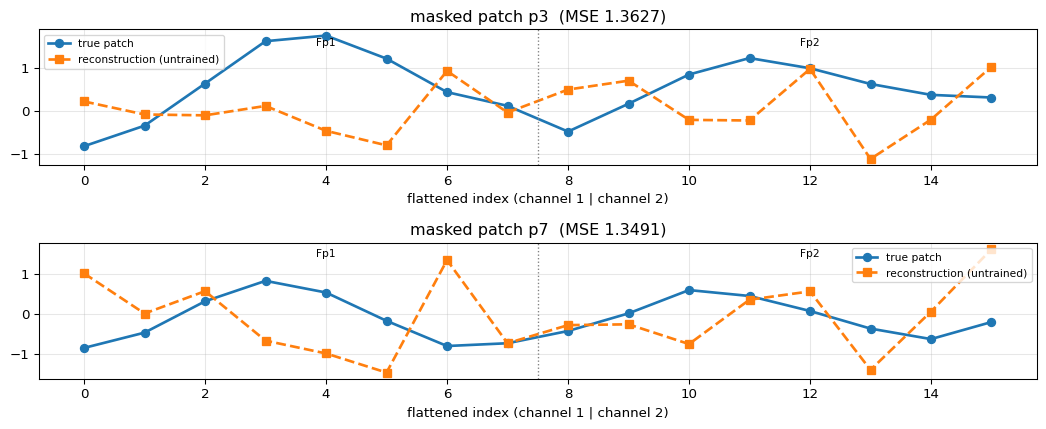

With random weights the reconstruction is unrelated to the target - as it
must be. Training is what closes that gap, and the loss above is the signal
that would drive it.


In [16]:
fig, axes = plt.subplots(len(mask_idx), 1, figsize=(11, 2.3 * len(mask_idx)),
                         squeeze=False)
for r, p in enumerate(mask_idx):
    ax = axes[r][0]
    xs = np.arange(PATCH_DIM)
    ax.plot(xs, patches[p], "o-", lw=2, label="true patch")
    ax.plot(xs, recon[p], "s--", lw=2, label="reconstruction (untrained)")
    ax.axvline(PATCH_LEN - .5, color="grey", ls=":", lw=1)
    ax.text(PATCH_LEN / 2, ax.get_ylim()[1] * .8, ch_names[0], ha="center", fontsize=8)
    ax.text(PATCH_LEN * 1.5, ax.get_ylim()[1] * .8, ch_names[1], ha="center", fontsize=8)
    ax.set(title=f"masked patch {patch_names[p]}  (MSE {per_patch[r]:.4f})",
           xlabel="flattened index (channel 1 | channel 2)")
    ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("With random weights the reconstruction is unrelated to the target - as it")
print("must be. Training is what closes that gap, and the loss above is the signal")
print("that would drive it.")

---
# 8. What `[CLS]` Is For

The reconstruction head is thrown away after pre-training. What survives is the encoder,
and the usual way to attach a classifier is through the `[CLS]` position:

$$\hat{y} = \sigma\big(H_{\texttt{[CLS]}} \, w_c + b_c\big)$$

`[CLS]` carries no signal of its own, so everything in it arrived through attention from
the patches. That is what makes it a whole-recording summary &mdash; useful for "does this
epoch contain a seizure?".

In [17]:
w_c, b_c = np.random.randn(D_MODEL) / np.sqrt(D_MODEL), 0.0
logit = float(H[0] @ w_c + b_c)
prob = 1 / (1 + np.exp(-logit))

print(f"H[CLS] = {np.round(H[0], 6)}\n")
print(f"logit = H_CLS . w_c + b_c")
print(f"      = {expand(H[0], w_c)}")
print(f"      = {logit:+.6f}")
print(f"\nP(seizure) = sigmoid({logit:+.6f}) = 1 / (1 + exp({-logit:+.6f})) = {prob:.6f}")

print(f"\n\nwhere [CLS] got its content - its attention row (head 0):\n")
print(f"{'attends to':>12}  {'weight':>9}")
print("-" * 24)
for j in range(n_seq):
    bar = "#" * int(A0[0, j] * 60)
    print(f"{seq_names[j]:>12}  {A0[0, j]:>9.4f}  {bar}")
print("-" * 24)
print(f"sum = {A0[0].sum():.6f}")
print(f"\n[CLS] began as a fixed learned vector identical for every recording.")
print(f"Everything that distinguishes one recording's [CLS] from another's came")
print(f"through these attention weights.")

H[CLS] = [-0.3946  1.3115 -0.2359 -0.2945 -1.8269 -0.2055  1.6127  0.0333]

logit = H_CLS . w_c + b_c
      = (-0.3946)*(-0.0796) + (+1.3115)*(+0.4269) + (-0.2359)*(+0.0815) + (-0.2945)*(+0.1528) + 
      (-1.8269)*(+0.1913) + (-0.2055)*(+0.0470) + (+1.6127)*(+0.1838) + (+0.0333)*(-0.0418)
      = +0.463005

P(seizure) = sigmoid(+0.463005) = 1 / (1 + exp(-0.463005)) = 0.613727


where [CLS] got its content - its attention row (head 0):

  attends to     weight
------------------------
       [CLS]     0.1081  ######
          p0     0.1568  #########
          p1     0.1121  ######
          p2     0.0689  ####
          p3     0.1127  ######
          p4     0.1253  #######
          p5     0.1307  #######
          p6     0.0746  ####
          p7     0.1107  ######
------------------------
sum = 1.000000

[CLS] began as a fixed learned vector identical for every recording.
Everything that distinguishes one recording's [CLS] from another's came
through these attention weights.


---
# 9. Summary

| Stage | Operation | Shape |
|---|---|---|
| Raw EEG | 2 channels x 64 samples | $(2, 64)$ |
| Patching | 8 patches of 8 samples, channels flattened | $(8, 16)$ |
| Patch embedding | $\text{patch}\,W_e + b_e$ | $(8, 8)$ |
| Add `[CLS]` + PE | prepend and add | $(9, 8)$ |
| Masking | 2 positions &rarr; `[MASK]` vector | $(9, 8)$ |
| Self-attention | $\mathrm{softmax}(QK^\top/\sqrt{d_k})V$, **no mask** | $(9, 9)$ weights |
| Encoder output $H$ | attention + FFN, each with Add & Norm | $(9, 8)$ |
| Reconstruction | $H_{1:}W_r + b_r$ | $(8, 16)$ |
| Loss | MSE on masked positions only | scalar |

**The one idea:** remove the causal mask and the model stops being a generator and
becomes an encoder. Prediction of the *next* item is replaced by reconstruction of a
*missing* one, which is a task that requires understanding context from both directions.

**Why this transfers to EEG so directly:** BERT never actually required words. It
required a sequence of vectors, a way to corrupt some of them, and a loss comparing the
reconstruction to the original. Patching supplies the vectors; MSE supplies the loss.
The attention mathematics is untouched.

**What is deliberately left out:** multiple stacked encoder layers (this is one block),
learned rather than sinusoidal positional embeddings, the 80/10/10 corruption applied
stochastically, GELU instead of ReLU, dropout, next-sentence prediction, and any actual
training &mdash; every weight here is random.

**Compared with the autoregressive Transformer walkthrough:**

| | Autoregressive (GPT-style) | BERT (this notebook) |
|---|---|---|
| Mask | causal, upper triangle $= -\infty$ | none |
| Context | left only | both directions |
| Task | predict the next token | reconstruct masked inputs |
| Loss | cross-entropy over vocabulary | MSE over the masked patches |
| Stacks | encoder + decoder | encoder only |
| Good at | generating sequences | representing them |